# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mahmarani/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

Research question: can a simple, transparent model help a FlyRank content reviewer decide which pages to look at first, by ranking pages whose 30-day impressions trend is declining, and does it beat a hand-written rule? Decision supported: which pages a human reviews first. Case study: FlyRank manages large portfolios of search content that ages and loses visibility, and reviewers cannot open every page.

## 2. Data

Source: FlyRank ML Internship anonymized sample (content_refresh_anonymized.csv, 44 columns), no client names, domains, URLs or keywords. 30,000 pages from 32 clients after keeping pages with impressions_90d > 0 and removing duplicate content IDs (no rows lost). The largest client holds 23.4% of rows. The full 79M-row release was not used. Label: is_declining = (trend_direction == "down"), base rate 0.542. Excluded for leakage: trend_pct, trend_direction and all *_last_30d and *_prev_30d columns.

## 3. Methodology
Signal checks: staleness vs 30-day trend = MIXED; CTR vs position = CONFIRMED. Baseline rule: 15% staleness + 45% volume + 40% CTR gap (percentile ranks). Models: Logistic Regression and Random Forest with median imputation, scaling and one-hot encoding. Validation: client-grouped splits (75/25, 10 seeds) so no client is in both train and test; a random row split is used only as a "before" reference. Queue scores: 5-fold GroupKFold, out-of-fold. Metrics: Precision@k and average precision. Leakage audit: no label-derived columns; strongest single feature reaches average precision 0.608 vs base rate 0.542; 90-day and last-30-day impressions correlate 0.92 (disclosed overlap).


## 4. Results (vs baseline)

Ten grouped splits, mean (std): P@50 0.770 (0.089) for Logistic Regression vs 0.668 (0.120) for the rule; average precision 0.647 vs 0.620. A random row split gave P@50 0.874, so it overstates performance on new clients. On one grouped split Random Forest was close to random order at the top (P@50 0.54 vs base rate 0.517) and did not justify its complexity. Modest and directional: the gaps are about one standard deviation.

## 5. Limitations

The label is one 30-day change and can be noise. The 90-day features overlap the label window. Few clients, unevenly sized (large drift scores between client groups), so results may not transfer to a new client. No time-based split. Several top pages combine huge impressions with CTR near 0.00 and may be artifacts. No causal claim: I did not test that any action improves performance. Decision-support only.

## 6. Ranked recommendations
Out-of-fold P@50 0.82, P@100 0.76, average precision 0.645 (base rate 0.542). Ranked actions, by observed decline rate among groups of at least 500 pages: (1) rewrite title/meta for page-1 pages with CTR far below peers (0.76, n=649); (2) targeted relevance update for positions 11-20 (0.61, n=3,897); (3) refresh review for stale but visible pages (0.60, n=7,095); (4) expand thin visible pages (0.78 but only n=426, treat with caution); (5) monitor the rest (0.49). Reviewing the top 100 queue pages found 79 declining vs about 54 at random. A human reviews every action; nothing is automated.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

Cloning into 'flyrank-ml-internship'...
remote: Enumerating objects: 221, done.
remote: Counting objects: 100% (221/221), done.
remote: Compressing objects: 100% (177/177), done.
remote: Total 221 (delta 104), reused 93 (delta 28), pack-reused 0 (from 0)
Receiving objects: 100% (221/221), 2.02 MiB | 16.98 MiB/s, done.
Resolving deltas: 100% (104/104), done.
/content/flyrank-ml-internship
w07_metrics.json not found; run the w07 notebook first


,random split,client-grouped
P@50,0.874,0.770
P@100,0.836,0.745
Avg precision,0.702,0.647


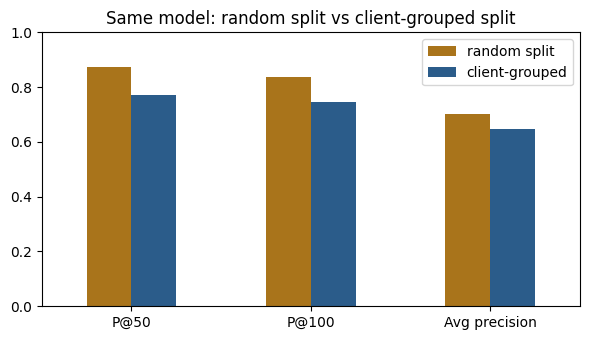

In [1]:
import os, json
if not os.path.exists("work/outputs"):
    !git clone https://github.com/mahmarani/flyrank-ml-internship.git
    %cd flyrank-ml-internship
import pandas as pd, matplotlib.pyplot as plt

try:
    print(json.load(open("work/outputs/w07_metrics.json")))
except FileNotFoundError:
    print("w07_metrics.json not found; run the w07 notebook first")

ba = pd.DataFrame({"random split": [0.874, 0.836, 0.702],
                   "client-grouped": [0.770, 0.745, 0.647]},
                  index=["P@50", "P@100", "Avg precision"])
display(ba)

os.makedirs("work/figures", exist_ok=True)
ax = ba.plot(kind="bar", figsize=(6, 3.5), color=["#A9741B", "#2B5C8A"])
ax.set_ylim(0, 1); ax.set_title("Same model: random split vs client-grouped split")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("work/figures/random_vs_grouped.png", dpi=150); plt.show()

Numbers copied from notebooks w05 to w07 and used in Figure 3 of the deployed paper.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.


## Demo outline (5 minutes)

**0:00–0:45 Question.** FlyRank’s reviewers cannot open every content page. Can a simple model help them decide which pages to look at first, and does it beat a rule they could read in one minute?

**0:45–1:45 Method.** Anonymized sample of 30,000 pages from 32 clients. Label: 30-day impressions trend is "down" (base rate 0.54). Baseline rule (staleness, volume, CTR gap) vs Logistic Regression vs Random Forest. Validation grouped by client, so no client appears in both training and test. Leakage checks on features.

**1:45–3:00 One chart.** Figure 3 in the paper: the same model under a random split (P@50 0.87) and a client-grouped split (P@50 0.77). Point: the random split flatters the model, so the honest number is the lower one.

**3:00–4:00 One honest result.** Across 10 grouped splits, Logistic Regression reached P@50 0.77 vs 0.67 for the rule (base rate 0.54). Modest edge, gap about one standard deviation, directional only. Random Forest did not justify its complexity.

**4:00–4:45 One recommendation.** Review the top 100 pages of the ranked queue first: 79 were declining vs about 54 expected at random (about 25 extra for roughly 25 review hours, my estimate). Start with page-1 pages whose CTR is far below their peers, and have a human check each page before any change.

**4:45–5:00 Limits and close.** Short 30-day label, overlapping 90-day features, few clients. Decision-support, not a prediction of rankings. Paper and code are public.

## Shareable cuts

### Social post (methodology)
I spent a few weeks on a FlyRank case study: can a model help content teams decide which pages to review first?

What I learned about method, more than about models:
• A random train/test split made my model look great (Precision@50 of 0.87). Splitting by client dropped it to 0.77. That drop was the honest number.
• A hand-written rule I could explain in one line was hard to beat. Logistic Regression edged it out (0.77 vs 0.67), but the gap is about one standard deviation, so I call it directional.
• A bigger model (Random Forest) did not help.
• I checked for leakage, wrote out the limits, and ended with a ranked review queue meant for human decisions.

Paper and code are public: https://mahmarani.github.io/flyrank-ml-internship/
#MachineLearning #DataScience #SEO

### Employer-facing summary (3 sentences)
I built and validated a ranking model for a content-review queue, comparing a hand-written baseline rule with Logistic Regression and Random Forest in scikit-learn on an anonymized FlyRank sample of 30,000 search content pages from 32 clients. Using client-grouped validation and a leakage audit, I showed that a random split overstated Precision@50 (0.87 vs 0.77) and that Logistic Regression ranked modestly better than the rule (0.77 vs 0.67, directional). I turned the results into a ranked, human-reviewed action playbook with limits and monitoring triggers, published as an open research paper with reproducible notebooks.